**Tarea 4** Notebook de métricas de clasificación.

*Introducción a Ciencia de Datos*

***María Guadalupe Villanueva Utrilla***

**Descripción y procedencia de dataset**

El dataset empleado para esta tarea ha sido recolectado de la empresa Bank Marketing (Moro et al., 2014), del UCI Machine Learning Repository. Dentro de bank-additional.zip, se tiene el archivo bank-additional-full.csv, separado por punto y coma, y su descripción, bank-additional-names.txt. La variable objetivo es y.






**Estos datos han sido recolectados por UCI Machine Learning Repository**

(https://archive.ics.uci.edu/static/public/222/bank+marketing.zip).


## Antes de modelar, revisar bank-additional-names.txt.

### Responder: ¿Hay alguna variable que el banco no podría conocer en el momento de decidir a quién llamar? Quítala y explica por qué.



In [8]:
import os                                  #manejar rutas y archivos
import urllib.request                      #descarga el dataset si hace falta
import numpy as np
import pandas as pd
import zipfile
import io
import requests                            #importar archivos desde url
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer   # aplica diferentes transformaciones a las columnas
from sklearn.pipeline import Pipeline           # organiza varios procesos en un solo flujo
from sklearn.preprocessing import OneHotEncoder, StandardScaler     # convierte variables categóricas en columnas numéricas, estandariza las variables numéricas
from sklearn.linear_model import LogisticRegression                 # modelo para clasificar entre dos clases
from sklearn.model_selection import train_test_split                # divide los datos en entrenamiento y prueba
from sklearn.metrics import (
    confusion_matrix,                   #muestra los aciertos y los errores de la clasificación
    accuracy_score,                     #proporción total de las predicciones correctas
    precision_score,                    #proporción de los positivos predichos que son correctos
    recall_score,                       #proporción de los positivos reales que se detectaron
    f1_score,                           #combina precisión y sensibilidad en una métrica
    roc_auc_score,                      #mide la capacidad del modelo para distinguir las clases
    average_precision_score,            #resume la curva de precisión y sensibilidad
    RocCurveDisplay,                    #para graficar la curva ROC|
    PrecisionRecallDisplay, )            #grafica precisión vs sensibilidad


pd.set_option("display.max_columns", None)  # muestra todas las columnas al revisar el dataframe

### Revisión

Aquí se cargan las librerías necesarias para trabajar con los datos y evaluar el modelo.

In [9]:
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

respuesta = requests.get(url)  # descarga el archivo oficial de uci
respuesta.raise_for_status()

with zipfile.ZipFile(io.BytesIO(respuesta.content)) as archivo:
    with zipfile.ZipFile(io.BytesIO(archivo.read("bank-additional.zip"))) as datos:
        df = pd.read_csv(datos.open("bank-additional/bank-additional-full.csv"), sep=";")

print("dimensiones:", df.shape)
display(df.head())with zipfile.ZipFile(io.BytesIO(respuesta.content)) as archivo:
    with zipfile.ZipFile(io.BytesIO(archivo.read("bank-additional.zip"))) as datos:
        descripcion = datos.read("bank-additional/bank-additional-names.txt").decode("utf-8", errors="ignore")  #lee la descripción

inicio = descripcion.lower().find("duration")  #busca la variable duration
print(descripcion[inicio:inicio + 750])        #muestra 750 caracteres desde esa posiciónwith zipfile.ZipFile(io.BytesIO(respuesta.content)) as archivo:
    with zipfile.ZipFile(io.BytesIO(archivo.read("bank-additional.zip"))) as datos:
        descripcion = datos.read("bank-additional/bank-additional-names.txt").decode("utf-8", errors="ignore")  #lee la descripción

inicio = descripcion.lower().find("duration")  #busca la variable duration
print(descripcion[inicio:inicio + 750])        #muestra 750 caracteres desde esa posición

dimensiones: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Revisión

El archivo contiene 41188 filas y 21 columnas y la variable objetivo es *y*, que nos dice si el cliente aceptó o no el depósito.

In [13]:
with zipfile.ZipFile(io.BytesIO(respuesta.content)) as archivo:
    with zipfile.ZipFile(io.BytesIO(archivo.read("bank-additional.zip"))) as datos:
        descripcion = datos.read("bank-additional/bank-additional-names.txt").decode("utf-8")

print(descripcion)  # muestra la descripción completa del dataset

﻿Citation Request:
  This dataset is publicly available for research. The details are described in [Moro et al., 2014]. 
  Please include this citation if you plan to use this database:

  [Moro et al., 2014] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, In press, http://dx.doi.org/10.1016/j.dss.2014.03.001

  Available at: [pdf] http://dx.doi.org/10.1016/j.dss.2014.03.001
                [bib] http://www3.dsi.uminho.pt/pcortez/bib/2014-dss.txt

1. Title: Bank Marketing (with social/economic context)

2. Sources
   Created by: Sérgio Moro (ISCTE-IUL), Paulo Cortez (Univ. Minho) and Paulo Rita (ISCTE-IUL) @ 2014
   
3. Past Usage:

  The full dataset (bank-additional-full.csv) was described and analyzed in:

  S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems (2014), doi:10.1016/j.dss.2014.03.001.
 
4. Relevant Information:

   This

### Variable que el banco no podría conocer en el momento de decidir a quién llamar.

Se hace el desglose de las variables que conforman el dataset, haciendo un análisis de ellas, se puede intuir que:
La variable que el banco no podría conocer para llamae es *duration*, porque esta es  la duración de la llamada que se hace, pero el banco no conoce ese valor cuando va a decidir a quién llamar.

## Apartar el 20 % de los datos para prueba, con una partición estratificada.
### ¿Qué exactitud obtiene un clasificador que siempre responde no?

###¿Qué dice eso de la exactitud como métrica en este problema?

In [16]:
print(df["y"].value_counts())
print()
print(df["y"].value_counts(normalize=True).round(4))

y
no     36548
yes     4640
Name: count, dtype: int64

y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


### Revisión

La clase positiva *yes* es minoría, se podría estimar que uno de cada nueve clientes acepta una oferta. Esto puede sugerir que la exactitud por sí misma puede ser falsa, pues un modelo podría acertar mucho por el hecho de predecir casi siempre *no*.

In [24]:
y = (df["y"] == "yes").astype(int)                # convierte yes o no a 1 o 0 (binario)
x = df.drop(columns=["y", "duration"])            # elimina objetivo y la variable duration

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,                               # reserva 20 % para prueba como se señala en las indicaciones
    random_state=42,                              # se hace reproducible la partición
    stratify=y)                                 # conserva la proporción de clases


print("Entrenamiento:", x_train.shape)
print("Prueba:", x_test.shape)
print("Proporción positiva en prueba:", round(y_test.mean(), 4))

Entrenamiento: (32950, 19)
Prueba: (8238, 19)
Proporción positiva en prueba: 0.1126


### Revisión

La partición es estratificada, por lo que la proporción de clientes que aceptan se mantiene prácticamente igual en entrenamiento y prueba. Esto hace que la evaluación sea más estable y evita que una de las particiones quede con una distribución poco representativa.


Resultan 19 columnas para el entrenamiento, teniendo que *y* es la variable objetivo y *duration* fue eliminada.
Así, se tiene que para el Entrenamiento se tienen (32950, 19), para la Prueba (8238, 19) y la respectiva proporción positiva de la prueba es de 0.1126

In [19]:
pred_no = np.zeros(len(y_test), dtype=int)         # clasificador que siempre responde no
baseline_accuracy = accuracy_score(y_test, pred_no)

print(f"exactitud del clasificador siempre no: {baseline_accuracy:.4f}")

exactitud del clasificador siempre no: 0.8874


### 2. Exactitud

Un clasificador que siempre contesta *no* tiene una exactitud alrededor de *89 %*, aunque no detecta a ningún cliente que sí aceptaría. Entonces, la exactitud no es suficiente en este caso, la clase positiva es pequeña y un valor alto puede esconder un modelo **no** adecuado para encontrar posibles compradores.

## Ajusta una regresión logística, con las variables categóricas en one-hot y el escalado dentro de un Pipeline. Con el umbral de 0.5, reporta en prueba la matriz de confusión y, a partir de ella, exactitud, precisión, sensibilidad, especificidad y F1.

###¿Cuál de esas métricas le importa más al banco, y por qué?

In [26]:
categoricas = x_train.select_dtypes(include="object").columns.tolist()
numericas = x_train.select_dtypes(exclude="object").columns.tolist()

preprocesamiento = ColumnTransformer(
    transformers=[ ("num", StandardScaler(), numericas),      #escalar las variables numéricas
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas), ])  #codificar a las categorías



modelo = Pipeline(
    steps=[("preprocesamiento", preprocesamiento),    #transformar los datos dentro del pipeline
        ("modelo", LogisticRegression(max_iter=2000, random_state=42)),])  # clasificador


modelo.fit(x_train, y_train)                       #ajustar todo el pipeline con entrenamiento

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('modelo', LogisticRegression(max_iter=2000, random_state=42))])

### Revisión
Se identifican las variables numéricas y categóricas y se aplica un escalado a las numéricas y una codificación One-Hot a las categóricas para que el modelo pueda trabajar con ellas.

Se entrenó la regresión logística utilizando los datos de entrenamiento. El Pipeline realiza todo este proceso de forma ordenada y aplicando las mismas transformaciones cuando después se evalúe el modelo con los datos de prueba.

El preprocesamiento queda dentro del mismo pipeline, de tal forma que el escalado y el one-hot se aprenden únicamente con los datos de entrenamiento.

In [31]:
prob_05 = modelo.predict_proba(x_test)[:, 1]       #probabilidad estimada de la clase positiva
pred_05 = (prob_05 >= 0.5).astype(int)             #aplica el umbral pedido de 0.5

cm = confusion_matrix(y_test, pred_05)            #compación de las predicciones con los valores reales
tn, fp, fn, tp = cm.ravel()                       #separa los verdaderos y falsos positivos, y los negativos

exactitud = accuracy_score(y_test, pred_05)       #proporción total de predicciones correctas
precision = precision_score(y_test, pred_05, zero_division=0)     #la proporción de positivos predichos que sí son positivos
sensibilidad = recall_score(y_test, pred_05)                      # #la proporción de positivos reales que el modelo logra identificar
especificidad = tn / (tn + fp)                                    #la proporción de negativos reales identificados de manera correcta
f1 = f1_score(y_test, pred_05)                                     #combina precisión y sensibilidad en una sola métrica

print("matriz de confusión:")
print(cm)
print()
print(f"exactitud:      {exactitud:.4f}")
print(f"precisión:      {precision:.4f}")
print(f"sensibilidad:   {sensibilidad:.4f}")
print(f"especificidad:  {especificidad:.4f}")
print(f"f1:             {f1:.4f}")

matriz de confusión:
[[7219   91]
 [ 725  203]]

exactitud:      0.9009
precisión:      0.6905
sensibilidad:   0.2188
especificidad:  0.9876
f1:             0.3322


### 3. Métricas con el umbral de 0.5

Evaluando el modelo con el umbral de 0.5, se obtiene la exactitud del 90.09 %, lo que dice que clasifica de manera correcta a la mayoría de los clientes. La sensibilidad fue de 21.88 %, ya que de los 928 clientes que sí aceptaron la oferta, el modelo solo notó de manera adecuada a 203.

La precisión fue del 69.05 %, lo que nos dice que de los clientes que el modelo predijo que aceptarían, aproximadamente 7/10 sí lo hicieron.

La especificidad alcanzó el 98.76%, lo cual dice que el modelo es bueno identificando a quienes no aceptarían la oferta.

La F1 fue de 33.22% algo bajo, que nos da razón de la falta de equilibrio entre la precisión y la sensibilidad, se porta bien el modelo, pero aún deja pasar a varios clientes interesados.

La sensibilidad es importante para el banco porque una sensibilidad baja significa que se está dejando pasar a muchos clientes que podrían aceptar la oferta. Aunque también se debe considerar la precisión, porque cada llamada tiene un costo y no conviene contactar a todos los clientes, pues el costo se aumenta mucho.

## Grafica la curva ROC y la curva de precisión contra sensibilidad, con su AUC y su precisión promedio. En scikit-learn, RocCurveDisplay y PrecisionRecallDisplay.

###¿Qué muestra la segunda que la primera esconde cuando los positivos son pocos?

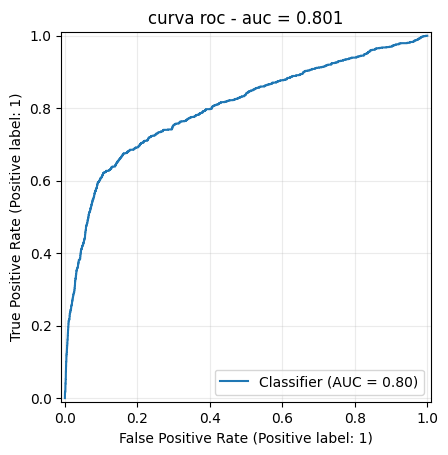

auc roc: 0.8008


In [54]:
roc_auc = roc_auc_score(y_test, prob_05)
RocCurveDisplay.from_predictions(y_test, prob_05)
plt.title(f"curva roc - auc = {roc_auc:.3f}")
plt.grid(alpha=0.25)
plt.show()

print(f"auc roc: {roc_auc:.4f}")

### Revisión de la curva ROC

La curva ROC ayuda a observar qué tan bien se distingue el modelo entre los clientes que aceptarían y los que no aceptarían la oferta, considerando diferentes umbrales de clasificación. Se obtuvo un AUC de 0.8008, lo que dice que el modelo tiene una capacidad relativamente buena para distinguir ambas clases (ya que está por encima del valor de 0.5).

Se puede observar que la curva se acerca a la esquina superior izquierda, pero aún hay un margen de mejora. El modelo tiene capacidad para identificar clientes interesados sin dar tantos falsos positivos.

Un AUC de 0.80 no significa que el modelo acierte el 80 % de las veces.
Como se tienen muchos más clientes que suelen rechazar la oferta, la curva ROC puede dar una idea a favor del modelo sin mostrar las dificultades para identificar a los clientes que sí aceptarían. Por eso también es importante analizar la curva de precisión contra sensibilidad.

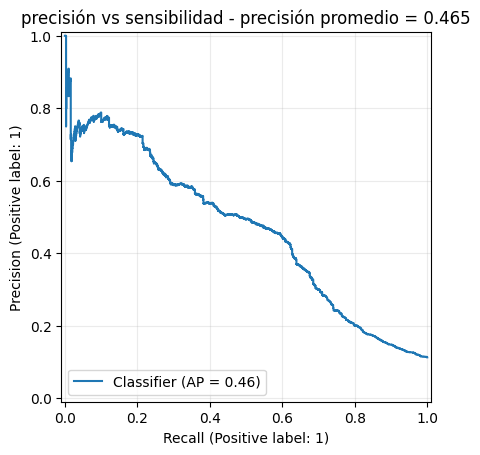

precisión promedio: 0.4648


In [33]:
ap = average_precision_score(y_test, prob_05)

PrecisionRecallDisplay.from_predictions(y_test, prob_05)
plt.title(f"precisión vs sensibilidad - precisión promedio = {ap:.3f}")
plt.grid(alpha=0.25)
plt.show()

print(f"precisión promedio: {ap:.4f}")

### 4. Precisión contra sensibilidad

En esta gráfica se puede ver cómo cambia la precisión del modelo conforme se intenta identificar a una mayor cantidad de clientes que aceptarían la oferta. Se tiene una precisión promedio de 0.4648, lo que dice que el modelo tiene cierta capacidad para identificar clientes interesados, aunque aún tiene limitaciones.
Conforme aumenta la sensibilidad, la precisión comienza a disminuir. Si se quiere identificar a más clientes que aceptarían, también se tienen que incluir a más personas que quizás podrían rechazar la oferta.

Esta gráfica nos deja ver mejor las complicaciones del modelo cuando hay pocos casos positivos. Aunque el modelo distingue bien entre ambas clases el encontrar a la mayoría de los clientes interesados sin realizar muchas llamadas innecesarias sigue siendo muy complejo.

In [38]:
costo_llamada = 5
ingreso_aceptacion = 50     #parámetros iniciales.

umbral_negocio = costo_llamada / ingreso_aceptacion  # punto de equilibrio esperado

print(f"umbral de punto de equilibrio: {umbral_negocio:.2f}")
print("conviene llamar cuando la probabilidad estimada es mayor a 0.10")

umbral de punto de equilibrio: 0.10
conviene llamar cuando la probabilidad estimada es mayor a 0.10


## Cada llamada cuesta 5, acepte o no el cliente, y cada cliente que acepta deja un ingreso de 50. ¿A partir de qué probabilidad conviene llamar?
###Compara en prueba la ganancia total con el umbral de 0.5 y con el tuyo.

### 5. ¿a partir de qué probabilidad conviene llamar?

Si una llamada cuesta 5 y una aceptación genera 50, el valor esperado de llamar es *50p - 5*. El punto de equilibrio estaría en *p = 0.10*, así que por arriba de 10% la llamada tiene ganancia que se espera positiva según los costos.

In [51]:
def calcular_ganancia(y_real, probabilidades, umbral):
    llamadas = probabilidades >= umbral             # decide a quién llamar
    n_llamadas = int(llamadas.sum())
    aceptaciones = int(np.asarray(y_real)[llamadas].sum())
    ganancia = aceptaciones * ingreso_aceptacion - n_llamadas * costo_llamada
    return n_llamadas, aceptaciones, ganancia

resultado_05 = calcular_ganancia(y_test, prob_05, 0.5)
resultado_010 = calcular_ganancia(y_test, prob_05, umbral_negocio)

comparacion_ganancia = pd.DataFrame([
        ["0.50", *resultado_05],
        ["0.10", *resultado_010],],
    columns=["umbral", "llamadas", "aceptaciones", "ganancia_total"])

display(comparacion_ganancia)

,umbral,llamadas,aceptaciones,ganancia_total
0,0.50,294,203,8680
1,0.10,1900,632,22100


### Comparación de ganancia

Al comparar los dos umbrales, podemos observar que con 0.5 se hicieron 294 llamadas y de las cuales 203 terminaron en siendo aceptación, lo que obtuvo una ganancia de 8,680. Al usar el umbral de 0.10 se realizaron 1,900 llamadas con 632 aceptaciones y una ganancia de 22,100.

Esto nos da una mejora de 13,420 en la ganancia, pero también resulta de realizar muchas más llamadas. El incremento de aceptaciones podría compensar el costo extra de contactar a más personas.

El umbral de 0.10 resulta ser mejor para el banco, ya que ayuda a encontrar a más clientes con interés y tener una mayor ganancia total. Podríamos probrar diferentes umbrales para buscar mejores resultados para el banco

## La variable que se quitó. Repetir el punto 3 incluyéndola.
### ¿Qué les pasa a las métricas? ¿Le servirían al banco?

In [55]:
x_con_duration = df.drop(columns=["y"])             # ahora se conserva duration a propósito

x_train_d, x_test_d, y_train_d, y_test_d = train_test_split(
    x_con_duration,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y)

categoricas_d = x_train_d.select_dtypes(include="object").columns.tolist()
numericas_d = x_train_d.select_dtypes(exclude="object").columns.tolist()

preprocesamiento_d = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numericas_d),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas_d)])

modelo_d = Pipeline(steps=[
        ("preprocesamiento", preprocesamiento_d),
        ("modelo", LogisticRegression(max_iter=2000, random_state=42))])

modelo_d.fit(x_train_d, y_train_d)
prob_d = modelo_d.predict_proba(x_test_d)[:, 1]
pred_d = (prob_d >= 0.5).astype(int)

### Revisión

En este segundo modelo se repite exactamente el procedimiento, pero ahora sí se incluye *duration*. Se puede estudiar cuánto se puede mejorar de manera artificial una evaluación cuando se introduce una variable que solo se conoce después de iniciar la llamada.

In [56]:
def resumen_metricas(y_real, pred, prob):
    tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
    return {
        "exactitud": accuracy_score(y_real, pred),
        "precisión": precision_score(y_real, pred, zero_division=0),
        "sensibilidad": recall_score(y_real, pred),
        "especificidad": tn / (tn + fp),
        "f1": f1_score(y_real, pred),
        "auc_roc": roc_auc_score(y_real, prob),
        "precisión_promedio": average_precision_score(y_real, prob)}

sin_duration = resumen_metricas(y_test, pred_05, prob_05)
con_duration = resumen_metricas(y_test_d, pred_d, prob_d)

comparacion_metricas = pd.DataFrame(
    [sin_duration, con_duration],
    index=["sin duration", "con duration"]).round(4)

display(comparacion_metricas)

print("matriz de confusión con duration:")
print(confusion_matrix(y_test_d, pred_d))

,exactitud,precisión,sensibilidad,especificidad,f1,auc_roc,precisión_promedio
sin duration,0.9009,0.6905,0.2188,0.9876,0.3322,0.8008,0.4648
con duration,0.9166,0.7118,0.4364,0.9776,0.5411,0.9424,0.6356


matriz de confusión con duration:
[[7146  164]
 [ 523  405]]


### 6. Repetir el modelo incluyendo `duration`

Comparando los modelos, se puede ver que al incluir la variable duration las métricas mejoran. La exactitud aumentó del 90.09% al 91.66% y la precisión pasa del 69.05% al 71.18%, mientras que la sensibilidad casi se duplicó, pasando del 21.88% al 43.64%. Esto podría significar que el segundo modelo logra encontrar a una mayor cantidad de clientes que aceptarían la oferta.

Analizando la especificidad, se nota que disminuye un poco y pasa del 98.76% al 97.76%, por lo que ahora se clasifican de manera incorrecta algunos clientes más que rechazarían la oferta. Para el F1, aumenta del 33.22% al 54.11%, con un mejor balance entre precisión y sensibilidad. También mejoraron el AUC ROC, de 0.8008 a 0.9424, y la precisión promedio, de 0.4648 a 0.6356.

Estos resultados parecen indicar que el segundo modelo es mejor, pero no sería lo mejor para el objetivo del banco, pues duration solo se sabe una vez realizada la llamada y se completa. Por lo que se reconoce que el primer modelo que aunque tiene métricas inferiores, es más acertado para decidir a qué clientes contactar pues utiliza información que sí estaría disponible antes de llamarlos.

## Conclusión

Se hizo un modelo de regresión logística para predecir qué clientes podrían aceptar una oferta ofrecida por un banco. Se pudo observar que aunque el modelo tuvo una exactitud del 90.09 %, no significa de forma necesaria que sea bueno encontrando a los clientes interesados, ya que solo logró detectar al 21.88% de quienes sí aceptaron la oferta.

Revisando las otras métricas y las curvas ROC y la de precisión contra sensibilidad, se ve que el modelo tiene una capacidad pasable para distinguir entre las dos clases, pero todavía tiene complicaciones para encontrar a los clientes que efectivamente sí aceptarían.

Comparando los umbrales de decisión, con un umbral de 0.10 en vez de 0.50, la ganancia sube, también se ve que incluir la variable duration mejora las métricas, pero no sería lo adecuado porque es un valor desconocido antes de realizar la llamada


**Declaración sobre el uso de inteligencia artificial**

Para la realización de esta práctica se utilizó *ChatGPT* como herramienta de soporte técnico, pedagógico y de redacción.
Alcance de uso:
* Soporte de código y resolución de errores.
* Entendimiento del datset y cómo importar su información, además de cómo importar el dataset mismo desde URL.
* Ayuda a entender las nuevas librerías utilizadas para esta práctica y el cómo son usadas.


